In [1]:
import os
import sys


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import seaborn as sns
import random
from pathlib import Path
from numpy.linalg import norm
import datetime
import math
import multiprocess as mp
import time
import pickle
import pyarrow.feather as feather
from scipy.signal import savgol_filter


In [2]:
DATADIR = Path.cwd().joinpath("lyaps")

In [3]:
lyaps_df_orig = feather.read_feather(Path(DATADIR, 'lyaps_erl.fea'))

In [18]:
lyaps_di = ["lyaps_erl_cycdi_0_0.fea", "lyaps_erl_cycdi_0_01.fea", "lyaps_erl_cycdi_0_05.fea", "lyaps_erl_cycdi_0_1.fea", "lyaps_erl_cycdi_0_2.fea", "lyaps_erl_cycdi_0_5.fea"]
mINT_di = ["mIMT_erl_cycdi_0_0.fea", "mIMT_erl_cycdi_0_01.fea", "mIMT_erl_cycdi_0_05.fea", "mIMT_erl_cycdi_0_1.fea", "mIMT_erl_cycdi_0_2.fea", "mIMT_erl_cycdi_0_5.fea"]

lyaps_bi = ["lyaps_erl_cycbi_0_01.fea", "lyaps_erl_cycbi_0_05.fea", "lyaps_erl_cycbi_0_1.fea", "lyaps_erl_cycbi_0_2.fea"]
mINT_bi = ["mIMT_erl_cycbi_0_01.fea", "mIMT_erl_cycbi_0_05.fea", "mIMT_erl_cycbi_0_1.fea", "mIMT_erl_cycbi_0_2.fea"]



In [6]:
def get_avgs(lyaps_df):
    all_lyap_avgs = []
    for row in range(len(lyaps_df)):
        tmp_pos = lyaps_df.iloc[row,:]
        lyap_avgs=[]
        for posit in range(len(tmp_pos[1])):
            d=[]
            for i in range(len(tmp_pos)):
                i+=1
                d.append(tmp_pos[i][posit])
            lyap_avgs.append(sum(d)/len(d))   
        all_lyap_avgs.append(lyap_avgs)
    
    return all_lyap_avgs

def fit_lyap(lyap_trace):
    t = np.linspace(0, 1000, 501)
    max_t=np.argmax(lyap_trace)
    #np.argmin(results[1][1][tmp:])
    min_t = min(lyap_trace[max_t:])
    min_r = math.ceil(min_t*10)/10
    min_inds = [i for i,v in enumerate(lyap_trace) if v <= min_r]
    if min_inds[0] > max_t:
        coef = np.polyfit(t[max_t:min_inds[0]],lyap_trace[max_t:min_inds[0]],1)
        poly1d_fn = np.poly1d(coef)   
    else:
        coef = np.polyfit(t,lyap_trace,1)
        poly1d_fn = np.poly1d(coef)   
    return coef[0]

In [7]:
def add_3Dlc(ax, z_lev, stiff, lyap_s, mINT):
    z = np.array([z_lev] * len(stiff))
    points = np.array([stiff, z, lyap_s]).T.reshape(-1, 1, 3)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    norm = plt.Normalize(20, 80)
    imt_arr = np.array(mINT[0])
    lc = Line3DCollection(segments, cmap='viridis', norm=norm, joinstyle="round", capstyle="round")
    lc.set_array(imt_arr)
    lc.set_array(imt_arr)
    lc.set_linewidth(3)
    line = ax.add_collection3d(lc, zs=z, zdir='z')
    return line

In [8]:
def plot_3Dlc(lyap_conds, mINT_conds):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')

    n = 0
    stiff = np.linspace(0,1,100)
    
    for (lyap_cond, mINT_cond) in zip(lyap_conds, mINT_conds):
        lyap = feather.read_feather(Path(DATADIR, lyap_cond))
        mINT = feather.read_feather(Path(DATADIR, mINT_cond))
        
        all_lyap_avgs = get_avgs(lyap)
        all_lyap_fits = []
        for run in all_lyap_avgs:
            all_lyap_fits.append(fit_lyap(run)) 
        lyap_s = savgol_filter(all_lyap_fits, 21, 3)  
        line = add_3Dlc(ax, n, stiff, lyap_s, mINT)
            
        n+=1  
        
    fig.colorbar(line, ax=ax, location='left')
    ax.set_zlim(-0.03, 0.005) 
    ax.set_ylim(0, 5) 
    #ax.view_init(elev=100, azim=0, roll=90)
    ax.set_xlabel('Stiffness', labelpad=5)
    ax.set_ylabel('', labelpad=5)
    ax.set_zlabel('Lyapunov Exponent', labelpad=15)

In [9]:
%matplotlib notebook

<IPython.core.display.Javascript object>


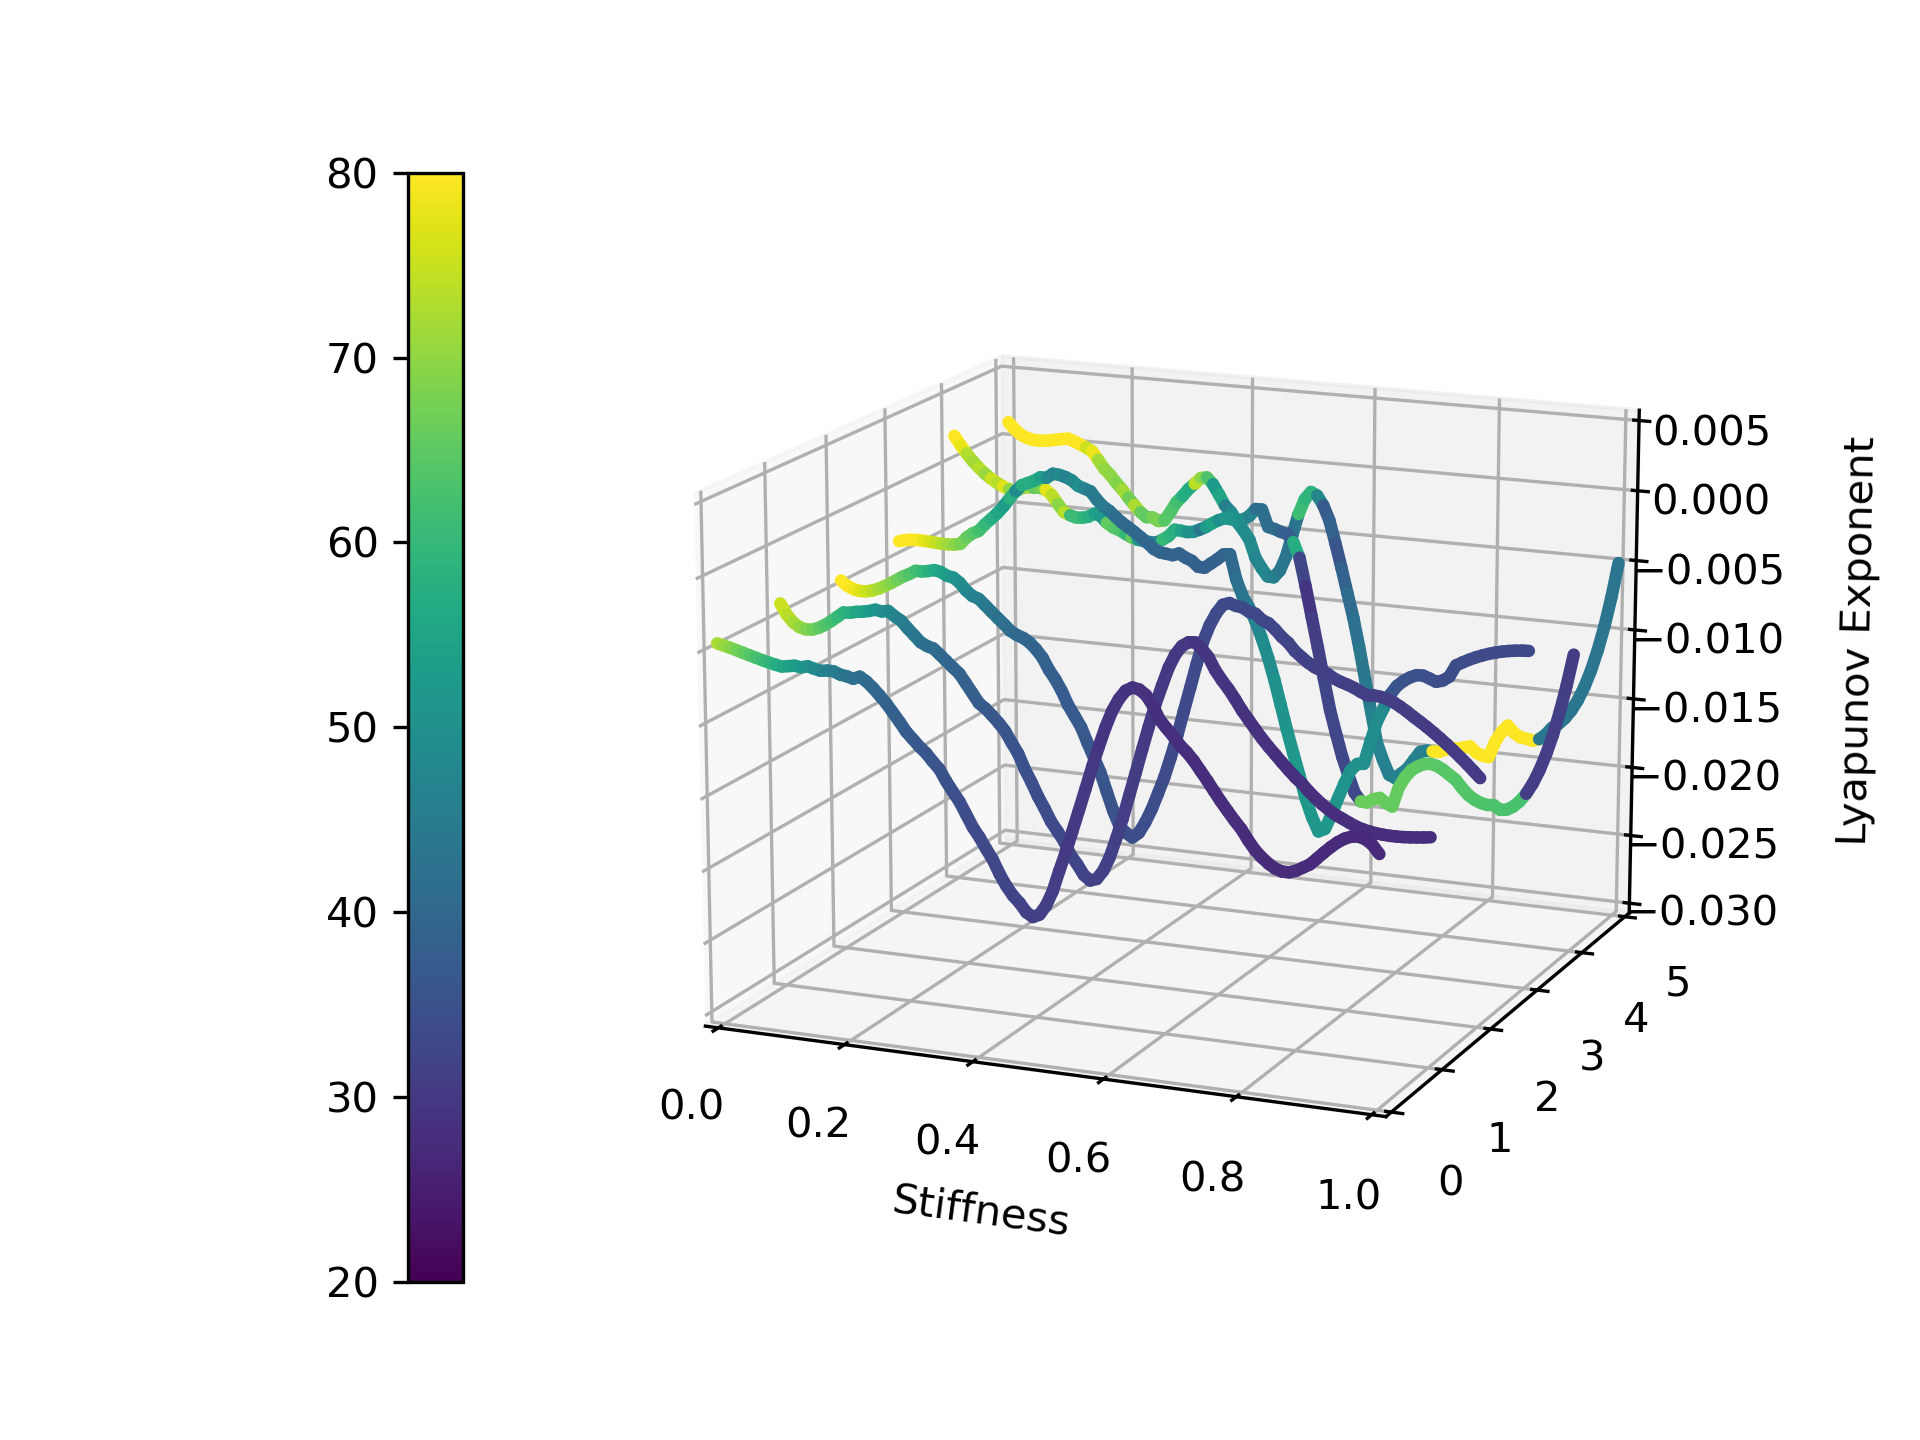

In [19]:
plot_3Dlc(lyaps_di, mINT_di)

<IPython.core.display.Javascript object>


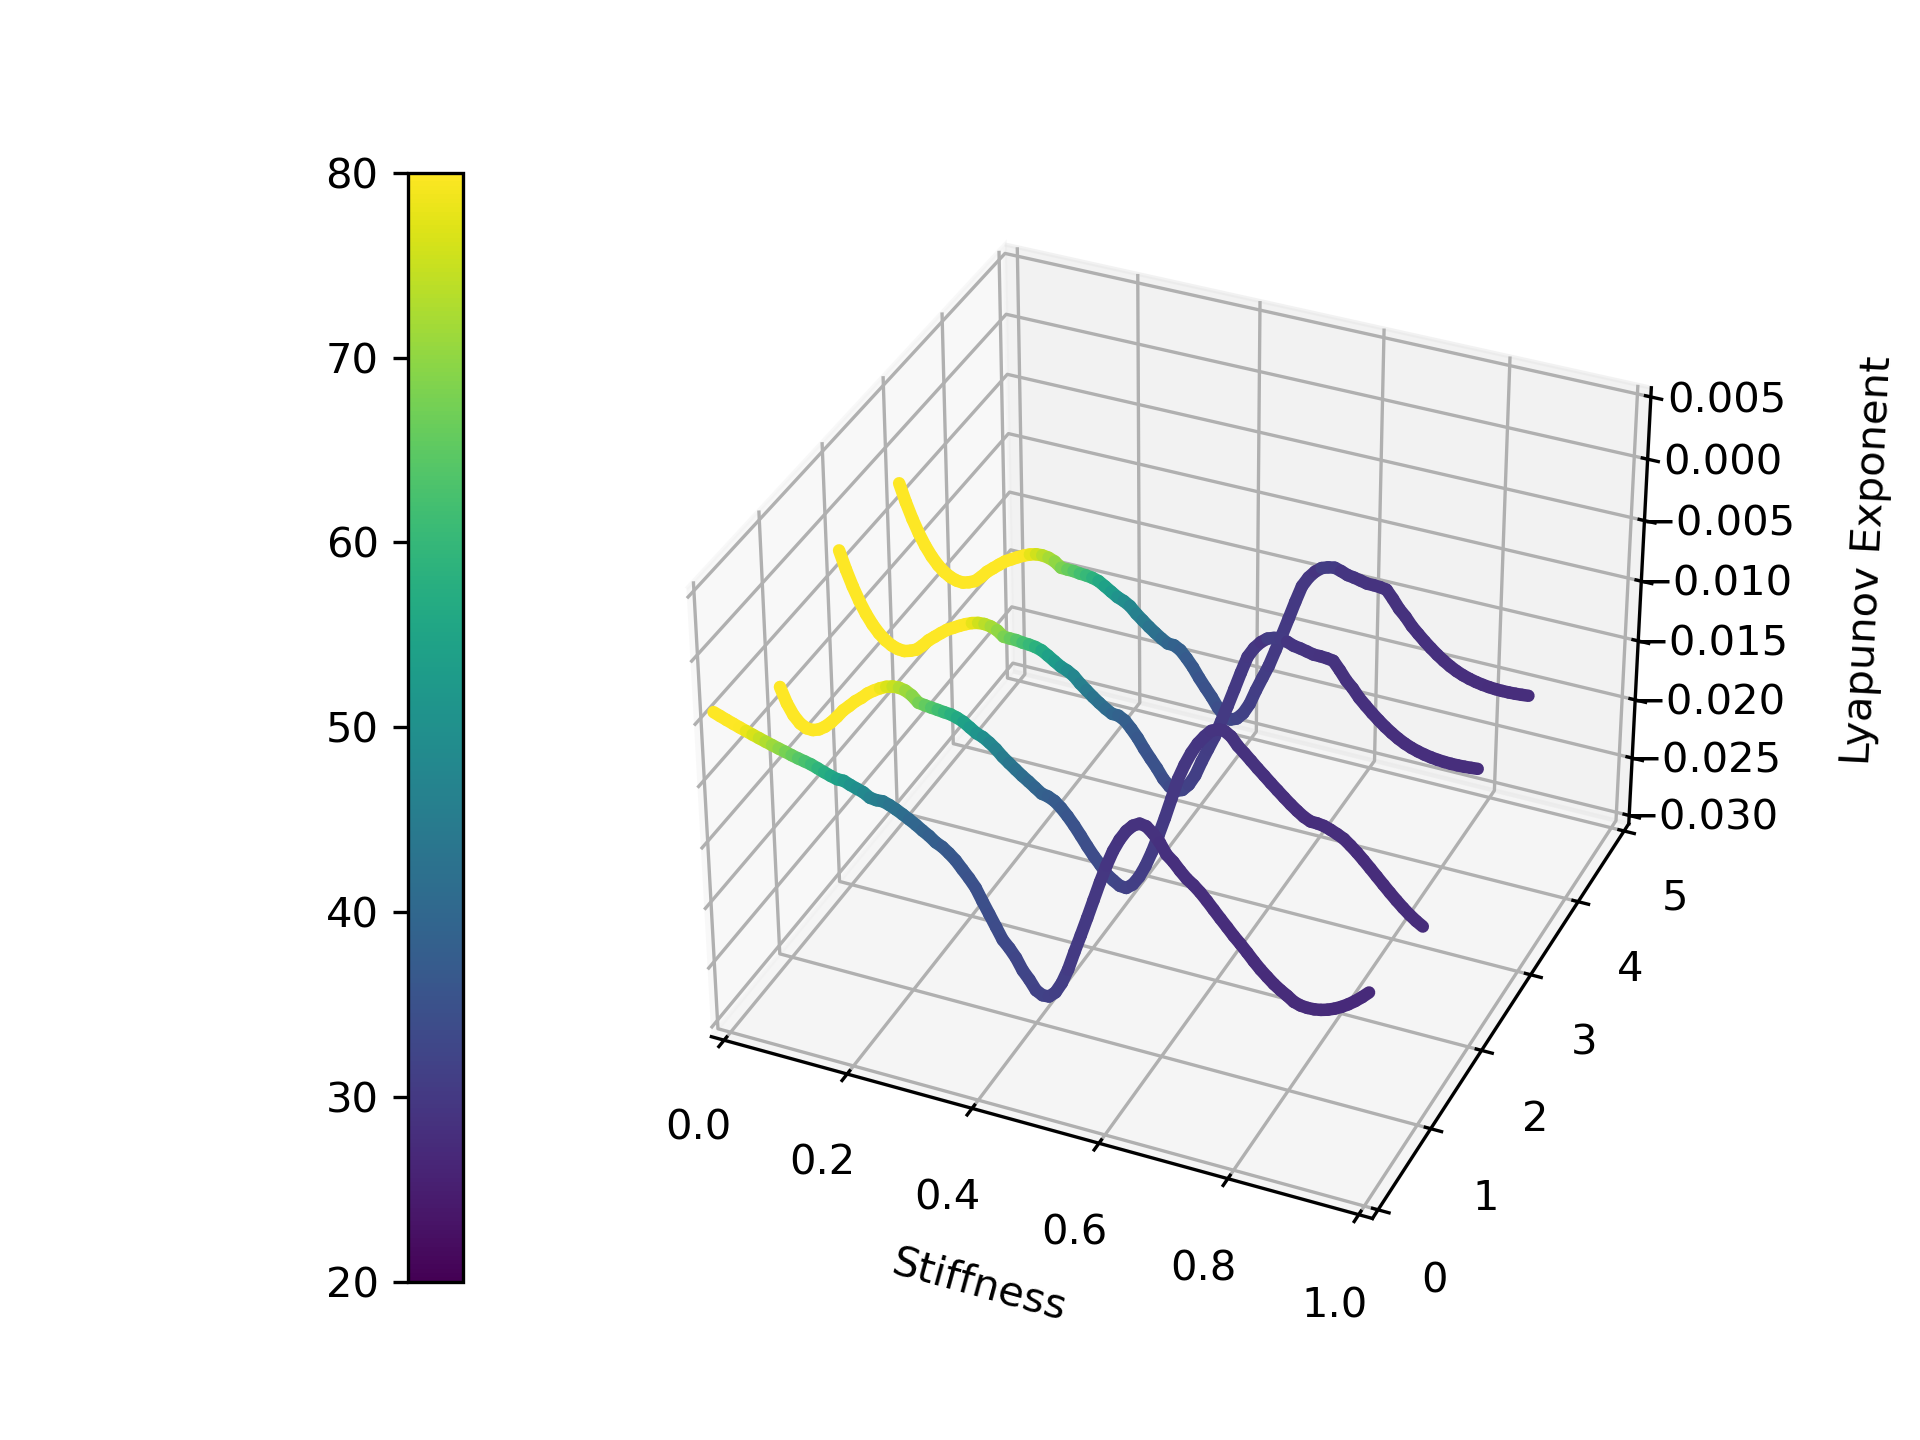

In [10]:
plot_3Dlc(lyaps_ei, mINT_ei)

In [15]:
lyap = feather.read_feather(Path(DATADIR, 'lyaps_erl_cycdi_0_01.fea'))
mINT = feather.read_feather(Path(DATADIR, 'mIMT_erl_cycdi_0_01.fea'))

In [16]:
all_lyap_avgs = get_avgs(lyap)

In [17]:
all_lyap_fits = []
for run in all_lyap_avgs:
    all_lyap_fits.append(fit_lyap(run)) 

In [18]:
stiff = np.linspace(0,1,100)
z = np.array([0] * len(stiff))
points = np.array([stiff, lyap_s, z]).T.reshape(-1, 1, 3)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
norm = plt.Normalize(20, 80)
imt_arr = np.array(mINT[0])
lc = Line3DCollection(segments, cmap='viridis', norm=norm)
lc.set_array(imt_arr)

ax = plt.figure().add_subplot(projection='3d')

lc.set_array(imt_arr)
lc.set_linewidth(3)
#line = ax.add_collection(lc)
ax.add_collection3d(lc, zs=z, zdir='z')

z = np.array([1] * len(stiff))
points = np.array([stiff, lyap_s, z]).T.reshape(-1, 1, 3)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
lc = Line3DCollection(segments, cmap='viridis', norm=norm)
lc.set_array(imt_arr)
lc.set_array(imt_arr)
lc.set_linewidth(3)
#line = ax.add_collection(lc)
ax.add_collection3d(lc, zs=z, zdir='z')

fig.colorbar(line, ax=ax)
plt.ylim(-0.025, 0.003)
ax.view_init(elev=100, azim=0, roll=90)




NameError: name 'stiff' is not defined

In [95]:
mINT

,0
0,75.103083
1,73.456154
2,71.813385
3,70.171154
4,68.526923
...,...
95,27.867343
96,27.854457
97,27.842457
98,27.831257


In [3]:
lyaps_df_orig_dmso = feather.read_feather('lyaps_dmso_orig.fea')
int_dmso = feather.read_feather('mIMT_dmso_orig.fea')

In [50]:
int_di

,0
0,83.679364
1,82.165083
2,80.649545
3,79.125000
4,77.584083
...,...
95,33.389207
96,33.335241
97,33.285621
98,33.239931


In [27]:
def get_avgs(lyaps_df):
    all_lyap_avgs = []
    for row in range(len(lyaps_df)):
        tmp_pos = lyaps_df.iloc[row,:]
        lyap_avgs=[]
        for posit in range(len(tmp_pos[1])):
            d=[]
            for i in range(len(tmp_pos)):
                i+=1
                d.append(tmp_pos[i][posit])
            lyap_avgs.append(sum(d)/len(d))   
        all_lyap_avgs.append(lyap_avgs)
    
    return all_lyap_avgs

In [5]:
def fit_lyap(lyap_trace):
    t = np.linspace(0, 1000, 501)
    max_t=np.argmax(lyap_trace)
    #np.argmin(results[1][1][tmp:])
    min_t = min(lyap_trace[max_t:])
    min_r = math.ceil(min_t*10)/10
    min_inds = [i for i,v in enumerate(lyap_trace) if v <= min_r]
    if min_inds[0] > max_t:
        coef = np.polyfit(t[max_t:min_inds[0]],lyap_trace[max_t:min_inds[0]],1)
        poly1d_fn = np.poly1d(coef)   
    else:
        coef = np.polyfit(t,lyap_trace,1)
        poly1d_fn = np.poly1d(coef)   
    return coef[0]

In [8]:
all_lyap_avgs_orig = get_avgs(lyaps_df_orig)
all_lyap_avgs_di = get_avgs(lyaps_df_di)
all_lyap_avgs_ei = get_avgs(lyaps_df_ei)
all_lyap_avgs_ai = get_avgs(lyaps_df_ai)
all_lyap_avgs_bi = get_avgs(lyaps_df_bi)

In [6]:
all_lyap_avgs_orig_dmso = get_avgs(lyaps_df_orig_dmso)

In [9]:
all_lyap_avgs_pso_0 = get_avgs(lyaps_df_pso_0)
all_lyap_avgs_pso_1 = get_avgs(lyaps_df_pso_1)

In [10]:
all_lyap_fits_orig = []
for lyap in all_lyap_avgs_orig:
    all_lyap_fits_orig.append(fit_lyap(lyap)) 
    
all_lyap_fits_di = []
for lyap in all_lyap_avgs_di:
    all_lyap_fits_di.append(fit_lyap(lyap)) 

all_lyap_fits_ei = []
for lyap in all_lyap_avgs_ei:
    all_lyap_fits_ei.append(fit_lyap(lyap)) 
    
all_lyap_fits_ai = []
for lyap in all_lyap_avgs_ai:
    all_lyap_fits_ai.append(fit_lyap(lyap)) 

all_lyap_fits_bi = []
for lyap in all_lyap_avgs_bi:
    all_lyap_fits_bi.append(fit_lyap(lyap)) 

In [11]:
all_lyap_fits_pso_0 = []
for lyap in all_lyap_avgs_pso_0:
    all_lyap_fits_pso_0.append(fit_lyap(lyap)) 
    
all_lyap_fits_pso_1 = []
for lyap in all_lyap_avgs_pso_1:
    all_lyap_fits_pso_1.append(fit_lyap(lyap)) 

In [7]:
all_lyap_fits_orig_dmso = []
for lyap in all_lyap_avgs_orig_dmso:
    all_lyap_fits_orig_dmso.append(fit_lyap(lyap)) 

(-0.025, 0.003)

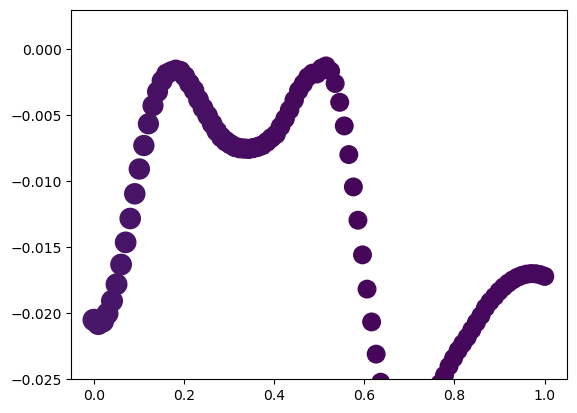

In [8]:
stiff = np.linspace(0,1,100)
int_sq = [n**2/3 for n in int_dmso[0]]
lyap_s = savgol_filter(all_lyap_fits_orig_dmso, 21, 3)
plt.scatter(stiff,lyap_s, c=int_dmso, s=int_sq, label='Orig Params')
plt.clim(20,120)
plt.ylim(-0.025, 0.003)

(-0.025, 0.003)

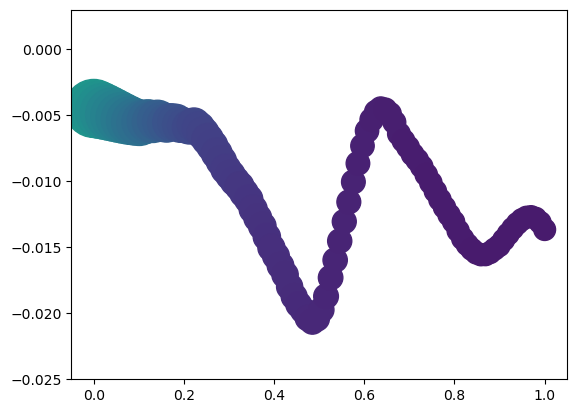

In [61]:
stiff = np.linspace(0,1,100)
int_sq = [n**2/3 for n in int_erl[0]]
lyap_s = savgol_filter(all_lyap_fits_orig, 21, 3)
plt.scatter(stiff,lyap_s, c=int_erl, s=int_sq, label='Orig Params')
plt.clim(20,120)
plt.ylim(-0.025, 0.003)

(-0.025, 0.003)

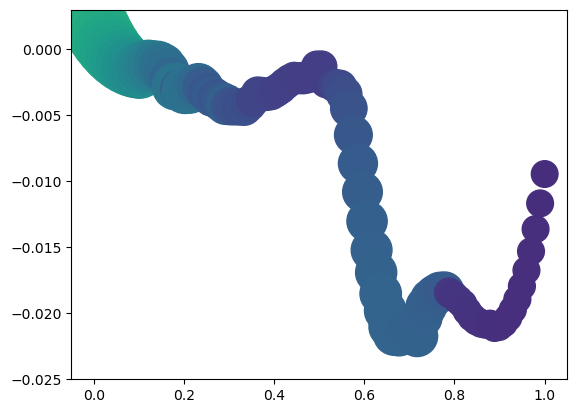

In [62]:
lyap_s = savgol_filter(all_lyap_fits_di, 21, 3)
int_sq = [n**2/3 for n in int_di[0]]
plt.scatter(stiff,lyap_s, c=int_di, s=int_sq, label='CycDi')
plt.clim(20,120)
plt.ylim(-0.025, 0.003)

(-0.025, 0.002)

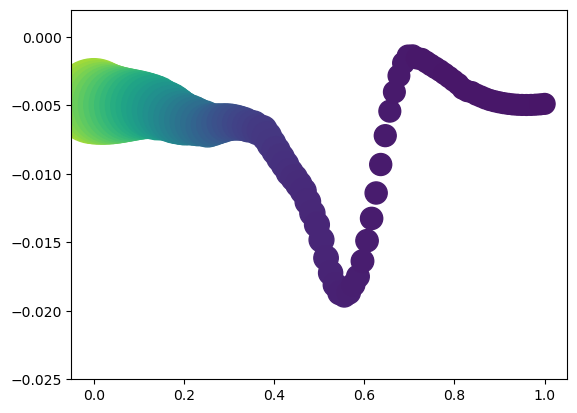

In [63]:
lyap_s = savgol_filter(all_lyap_fits_ei, 21, 3)
int_sq = [n**2/3 for n in int_ei[0]]
plt.scatter(stiff,lyap_s, c=int_ei, s=int_sq, label='CycEi')
plt.clim(20,120)
plt.ylim(-0.025, 0.002)

(-0.025, 0.002)

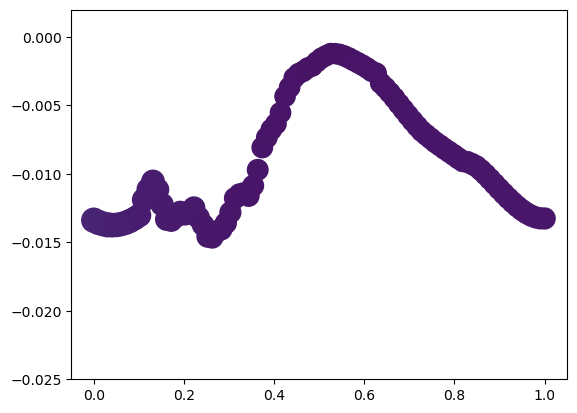

In [64]:
lyap_s = savgol_filter(all_lyap_fits_ai, 21, 3)
int_sq = [n**2/3 for n in int_ai[0]]
plt.scatter(stiff,lyap_s, c=int_ai, s=int_sq, label='CycAi')
plt.clim(20,120)
plt.ylim(-0.025, 0.002)

(-0.025, 0.002)

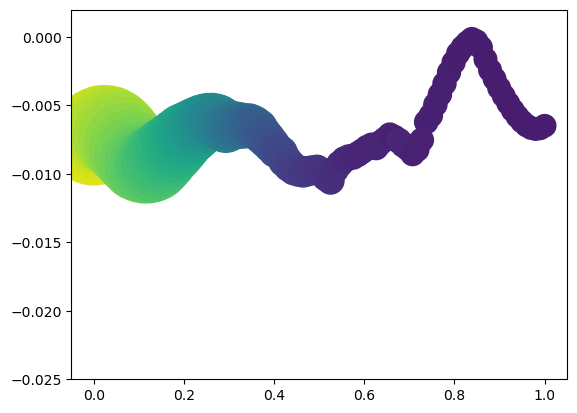

In [65]:
lyap_s = savgol_filter(all_lyap_fits_bi, 21, 3)
int_sq = [n**2/3 for n in int_bi[0]]
plt.scatter(stiff,lyap_s, c=int_bi, s=int_sq, label='CycBi')
plt.clim(20,120)
plt.ylim(-0.025, 0.002)

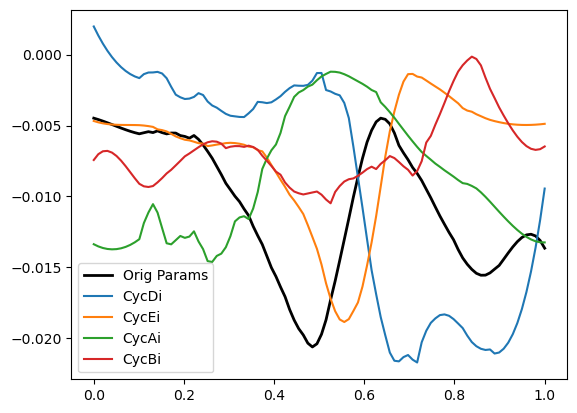

In [12]:
stiff = np.linspace(0,1,100)
lyap_s = savgol_filter(all_lyap_fits_orig, 21, 3)
plt.plot(stiff,lyap_s, lw=2, c='k', label='Orig Params')

lyap_s = savgol_filter(all_lyap_fits_di, 21, 3)
plt.plot(stiff,lyap_s, label='CycDi')

lyap_s = savgol_filter(all_lyap_fits_ei, 21, 3)
plt.plot(stiff,lyap_s, label='CycEi')

lyap_s = savgol_filter(all_lyap_fits_ai, 21, 3)
plt.plot(stiff,lyap_s, label='CycAi')

lyap_s = savgol_filter(all_lyap_fits_bi, 21, 3)
plt.plot(stiff,lyap_s, label='CycBi')


plt.legend()


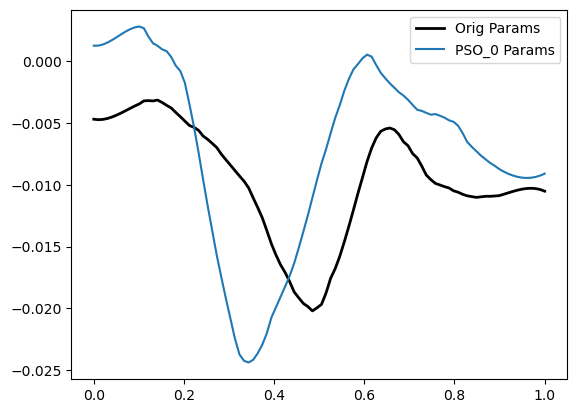

In [48]:
stiff = np.linspace(0,1,100)
lyap_s = savgol_filter(all_lyap_fits_orig, 21, 3)
plt.plot(stiff,lyap_s, lw=2, c='k', label='Orig Params')

stiff = np.linspace(0,1,100)
lyap_s = savgol_filter(all_lyap_fits_pso_0, 21, 3)
plt.plot(stiff,lyap_s, label='PSO_0 Params')



plt.legend()

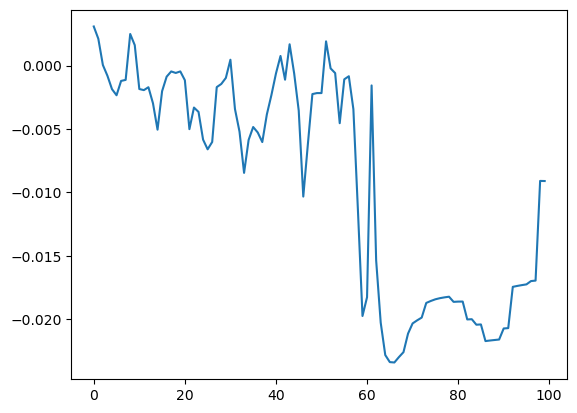

In [121]:
plt.plot(all_lyap_fits)

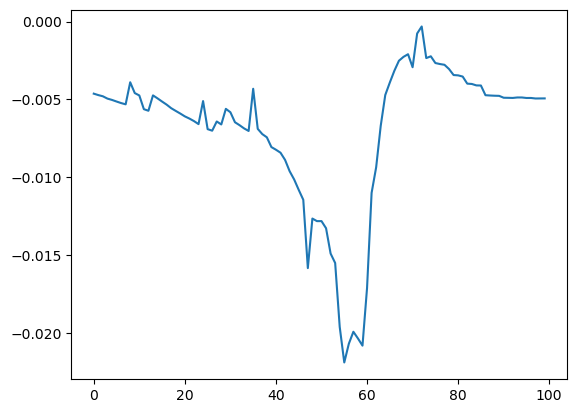

In [127]:
plt.plot(all_lyap_fits)

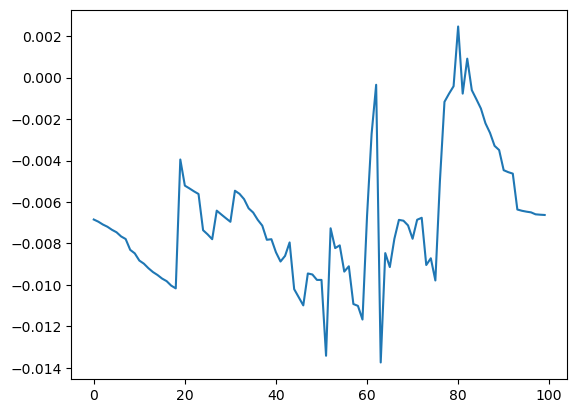

In [133]:
plt.plot(all_lyap_fits)

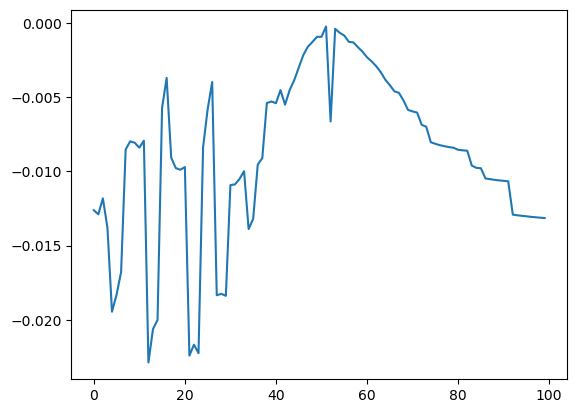

In [146]:
plt.plot(all_lyap_fits)



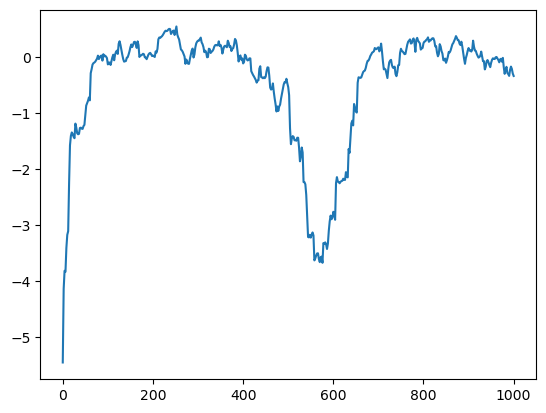

In [110]:
plt.plot(t, lyap_avgs[0])
#plt.plot(t[max_t:min_inds[0]], poly1d_fn(t[max_t:min_inds[0]]))